# 06 · Autoencoder variacional (VAE) en Fashion-MNIST

**Curso:** Fundamentos de Programación para la Inteligencia Artificial · **Autor:** William Lu Bjornestad

---

El cuaderno 05 terminó con una limitación: el espacio latente de un autoencoder agrupa las clases, pero no está organizado para **generar**. No se sabe de qué distribución muestrear, y las regiones entre grupos no corresponden necesariamente a imágenes válidas. El **autoencoder variacional** resuelve ambos problemas imponiendo una distribución conocida sobre el espacio latente, lo que lo convierte en un **modelo generativo**.

**Objetivos**

- Derivar la función de pérdida del VAE (ELBO) e implementar el truco de reparametrización.
- Estudiar el compromiso entre reconstrucción y regularidad del espacio latente (peso $\beta$).
- Generar imágenes nuevas, interpolar entre clases y comparar la representación con la del DAE.

**Conceptos de pipeline de ML introducidos**

| Etapa | Qué se ve en este cuaderno |
|---|---|
| Pérdidas compuestas | Monitorizar por separado cada término de la pérdida |
| Barrido de un hiperparámetro crítico | $\beta$ y sus efectos en varias métricas a la vez |
| Inferencia determinista | Usar la media $\mu$ al evaluar, en lugar de una muestra aleatoria |
| Diagnóstico del modelo | Unidades latentes activas y KL por dimensión |
| Evaluación comparativa | El mismo pipeline KNN del cuaderno 05 para comparar DAE y VAE |
| Modelo desplegable | Guardar el decodificador y generar muestras desde el *checkpoint* |

In [1]:
import copy
import time
from pathlib import Path

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from torchvision import datasets
import matplotlib.pyplot as plt
from matplotlib.patches import Ellipse
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

SEED = 42
torch.manual_seed(SEED)
DATA_DIR = "../data"
CKPT_DIR = Path("../checkpoints")
CKPT_DIR.mkdir(exist_ok=True)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Dispositivo: {device}")

CLASSES = ["T-shirt/top", "Trouser", "Pullover", "Dress", "Coat", "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"]

Dispositivo: cuda


## 1. Fundamento teórico

### Un modelo generativo con variables latentes

El VAE supone que cada imagen $x$ se genera en dos pasos: primero se elige un vector latente $z \sim p(z) = \mathcal{N}(0, I)$ y después el decodificador produce la imagen, $x \sim p_\theta(x \mid z)$. Si el modelo está bien entrenado, **generar imágenes nuevas es tan simple como muestrear $z$ de una normal estándar y decodificarlo**.

Para entrenarlo hace falta la distribución a posteriori $p(z \mid x)$ (qué vectores latentes pudieron generar una imagen), pero es intratable. La **inferencia variacional** la aproxima con una distribución sencilla que predice el codificador:

$$q_\phi(z \mid x) = \mathcal{N}\big(z;\ \mu_\phi(x),\ \operatorname{diag}\sigma^2_\phi(x)\big)$$

Así, el codificador ya no devuelve un punto, sino una **distribución**: una media $\mu$ y una varianza $\sigma^2$ por dimensión. En la práctica se predice $\log \sigma^2$, que puede tomar cualquier valor real.

### La función de pérdida: ELBO

Maximizar la verosimilitud de los datos equivale a maximizar una cota inferior (*Evidence Lower BOund*):

$$\log p_\theta(x) \ \ge\ \underbrace{\mathbb{E}_{q_\phi(z \mid x)}\big[\log p_\theta(x \mid z)\big]}_{\text{reconstrucción}} \ -\ \underbrace{D_{KL}\big(q_\phi(z \mid x)\ \|\ p(z)\big)}_{\text{regularización}}$$

- Con una verosimilitud gaussiana, el término de reconstrucción es, salvo constantes, el **error cuadrático** entre la imagen y su reconstrucción.
- La divergencia KL entre dos gaussianas tiene forma cerrada: $D_{KL} = -\tfrac{1}{2}\sum_{j}\big(1 + \log\sigma_j^2 - \mu_j^2 - \sigma_j^2\big)$.

La KL empuja la distribución de **cada** imagen hacia $\mathcal{N}(0, I)$. No sabe nada de clases: lo que hace es que el espacio latente sea **compacto y continuo**, sin huecos entre regiones, porque cada imagen ocupa una "nube" alrededor de su media en lugar de un punto aislado. La agrupación por clases sigue saliendo del término de reconstrucción.

La pérdida final que se minimiza es $\mathcal{L} = \text{MSE} + \beta \cdot D_{KL}$. El peso $\beta$ equilibra los dos objetivos, porque su escala relativa depende de cómo se mida la reconstrucción (aquí, la suma sobre los 784 píxeles de cada imagen).

In [2]:
def vae_loss(x_hat, x, mu, logvar, beta):
    recon = F.mse_loss(x_hat, x, reduction="sum") / x.size(0)                     # error por imagen
    kl = (-0.5 * (1 + logvar - mu.pow(2) - logvar.exp()).sum(dim=1)).mean()      # KL por imagen
    return recon + beta * kl, recon, kl

### El truco de reparametrización

Para entrenar hay que muestrear $z \sim q_\phi(z \mid x)$, y el muestreo es una operación **no diferenciable**: el gradiente no puede atravesar "tira un dado" hasta $\mu$ y $\sigma$. La solución es reescribir la muestra como

$$z = \mu + \sigma \odot \varepsilon, \qquad \varepsilon \sim \mathcal{N}(0, I)$$

La aleatoriedad pasa a una entrada externa ($\varepsilon$) que no depende de los parámetros, y $z$ se convierte en una función **determinista y diferenciable** de $\mu$ y $\sigma$. La distribución de $z$ es exactamente la misma, pero ahora la retropropagación funciona.

In [3]:
class VAE(nn.Module):
    def __init__(self, latent_dim=8):
        super().__init__()
        self.latent_dim = latent_dim
        self.encoder = nn.Sequential(
            nn.Flatten(),
            nn.Linear(28 * 28, 128), nn.BatchNorm1d(128), nn.LeakyReLU(),
            nn.Linear(128, 32), nn.BatchNorm1d(32), nn.LeakyReLU(),
        )
        self.fc_mu = nn.Linear(32, latent_dim)
        self.fc_logvar = nn.Linear(32, latent_dim)
        self.decoder = nn.Sequential(
            nn.Linear(latent_dim, 32), nn.BatchNorm1d(32), nn.LeakyReLU(),
            nn.Linear(32, 128), nn.BatchNorm1d(128), nn.LeakyReLU(),
            nn.Linear(128, 28 * 28), nn.Sigmoid(),
            nn.Unflatten(1, (1, 28, 28)),
        )

    def encode(self, x):
        h = self.encoder(x)
        return self.fc_mu(h), self.fc_logvar(h)

    def reparameterize(self, mu, logvar):
        std = torch.exp(0.5 * logvar)
        return mu + std * torch.randn_like(std)

    def forward(self, x):
        mu, logvar = self.encode(x)
        return self.decoder(self.reparameterize(mu, logvar)), mu, logvar

## 2. Datos

Mismos datos y misma partición (semilla) que en el cuaderno 05, sin ruido: el VAE reconstruye la imagen limpia.

In [4]:
def load_split(train):
    ds = datasets.FashionMNIST(DATA_DIR, train=train, download=True)
    return (ds.data.float() / 255.0).unsqueeze(1), ds.targets


x_all, y_all = load_split(train=True)
x_test, y_test = load_split(train=False)
perm = torch.randperm(len(x_all), generator=torch.Generator().manual_seed(SEED))
val_idx, train_idx = perm[:6000], perm[6000:]
x_train, y_train = x_all[train_idx].to(device), y_all[train_idx].numpy()
x_val = x_all[val_idx].to(device)
x_test, y_test = x_test.to(device), y_test.numpy()
print(f"Entrenamiento: {len(x_train)} | validación: {len(x_val)} | test: {len(x_test)}")

Entrenamiento: 54000 | validación: 6000 | test: 10000


## 3. Entrenamiento

El bucle registra **por separado** los dos términos de la pérdida. Con una pérdida compuesta, el total puede bajar porque mejora un término mientras el otro empeora, y solo viéndolos por separado se entiende qué está aprendiendo el modelo.

In [5]:
def batches(x, batch_size, shuffle=False):
    idx = torch.randperm(len(x), device=x.device) if shuffle else torch.arange(len(x), device=x.device)
    for i in range(0, len(x), batch_size):
        yield x[idx[i:i + batch_size]]


def run_epoch(model, x, beta, optimizer=None, batch_size=128):
    training = optimizer is not None
    model.train(training)
    totals = np.zeros(3)
    with torch.set_grad_enabled(training):
        for xb in batches(x, batch_size, shuffle=training):
            x_hat, mu, logvar = model(xb)
            loss, recon, kl = vae_loss(x_hat, xb, mu, logvar, beta)
            if training:
                optimizer.zero_grad()
                loss.backward()
                optimizer.step()
            totals += np.array([loss.item(), recon.item(), kl.item()]) * len(xb)
    return dict(zip(["loss", "recon", "kl"], totals / len(x)))


def fit(beta, epochs=40, lr=1e-3, verbose=True):
    torch.manual_seed(SEED)
    model = VAE(latent_dim=8).to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    history = {"train": [], "val": []}
    best_val, best_state = float("inf"), None
    start = time.time()
    for epoch in range(1, epochs + 1):
        history["train"].append(run_epoch(model, x_train, beta, optimizer))
        history["val"].append(run_epoch(model, x_val, beta))
        if history["val"][-1]["loss"] < best_val:
            best_val, best_state = history["val"][-1]["loss"], copy.deepcopy(model.state_dict())
        if verbose and (epoch == 1 or epoch % 10 == 0):
            t, v = history["train"][-1], history["val"][-1]
            print(f"Época {epoch:>3} | train {t['loss']:.3f} (rec {t['recon']:.3f}, KL {t['kl']:.3f}) | val {v['loss']:.3f}")
    model.load_state_dict(best_state)
    print(f"beta = {beta}: mejor val {best_val:.3f} | tiempo {time.time() - start:.1f} s")
    return model, history

### Barrido de $\beta$

En la primera versión de esta práctica se usó $\beta = 0.01$. Aquí se entrenan tres modelos idénticos con $\beta \in \{0.01,\ 0.1,\ 1\}$ para ver el compromiso de forma cuantitativa.

In [6]:
BETAS = [0.01, 0.1, 1.0]
vaes, histories = {}, {}
for beta in BETAS:
    print(f"\n=== beta = {beta} ===")
    vaes[beta], histories[beta] = fit(beta)


=== beta = 0.01 ===


Época   1 | train 32.915 (rec 32.746, KL 16.935) | val 20.088


Época  10 | train 13.242 (rec 12.934, KL 30.798) | val 12.696


Época  20 | train 12.425 (rec 12.123, KL 30.196) | val 11.971


Época  30 | train 12.064 (rec 11.762, KL 30.219) | val 11.685


Época  40 | train 11.841 (rec 11.538, KL 30.310) | val 11.527
beta = 0.01: mejor val 11.501 | tiempo 130.6 s

=== beta = 0.1 ===


... (6 outputs left out)

Época  10 | train 25.515 (rec 18.381, KL 7.134) | val 25.076


Época  20 | train 24.948 (rec 17.660, KL 7.287) | val 24.580


Época  30 | train 24.681 (rec 17.299, KL 7.381) | val 24.372


Época  40 | train 24.502 (rec 17.082, KL 7.419) | val 24.191
beta = 1.0: mejor val 24.167 | tiempo 98.1 s


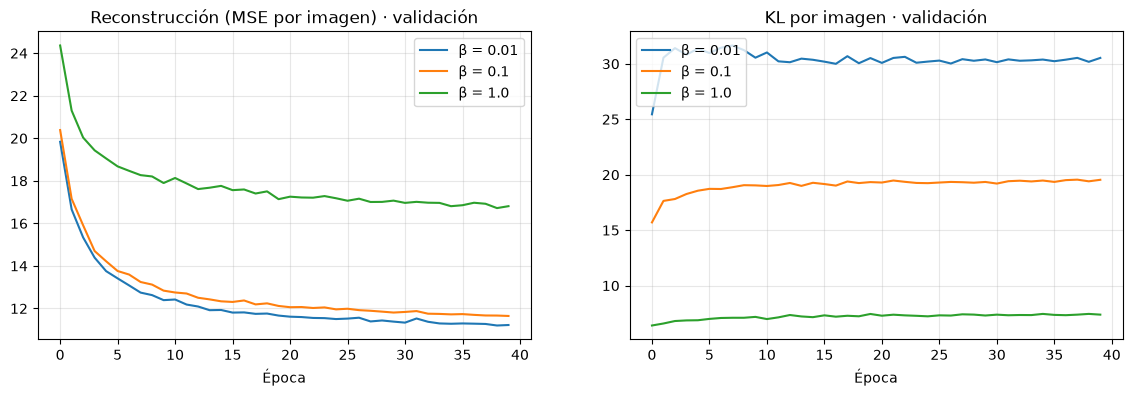

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for beta in BETAS:
    h = histories[beta]
    axes[0].plot([e["recon"] for e in h["val"]], label=f"β = {beta}")
    axes[1].plot([e["kl"] for e in h["val"]], label=f"β = {beta}")
axes[0].set_title("Reconstrucción (MSE por imagen) · validación")
axes[1].set_title("KL por imagen · validación")
for ax in axes:
    ax.set_xlabel("Época")
    ax.grid(True, alpha=0.3)
    ax.legend()
plt.show()

## 4. Evaluación

Para evaluar se usa el modo **determinista**: se codifica cada imagen con su media $\mu$ y se decodifica esa media, sin muestrear. Si se usara una muestra aleatoria, las métricas cambiarían de una ejecución a otra.

Se calculan cuatro indicadores por modelo:

- **MSE de reconstrucción por píxel** en test.
- **KL media** por imagen: cuánta información codifica el espacio latente, medida en *nats*.
- **Unidades activas**: dimensiones latentes cuya media $\mu_j$ varía de verdad entre imágenes ($\operatorname{Var}_x[\mu_j(x)] > 0.01$). Una dimensión inactiva ha "colapsado" al prior: el codificador la ignora y el decodificador no la usa.
- **Exactitud KNN** sobre $\mu$, con el mismo pipeline del cuaderno 05.

In [8]:
def encode_mu(model, x, batch_size=1024):
    model.eval()
    with torch.no_grad():
        mus, logvars = zip(*(model.encode(x[i:i + batch_size]) for i in range(0, len(x), batch_size)))
    return torch.cat(mus), torch.cat(logvars)


def decode(model, z, batch_size=1024):
    model.eval()
    with torch.no_grad():
        return torch.cat([model.decoder(z[i:i + batch_size]) for i in range(0, len(z), batch_size)])


def knn_accuracy(model):
    pipe = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=5))
    pipe.fit(encode_mu(model, x_train)[0].cpu().numpy(), y_train)
    return pipe.score(encode_mu(model, x_test)[0].cpu().numpy(), y_test)


metrics = {}
for beta, model in vaes.items():
    mu, logvar = encode_mu(model, x_test)
    kl_per_dim = (-0.5 * (1 + logvar - mu.pow(2) - logvar.exp())).mean(dim=0)
    metrics[f"β = {beta}"] = {
        "MSE por píxel": ((decode(model, mu) - x_test) ** 2).mean().item(),
        "KL (nats)": kl_per_dim.sum().item(),
        "unidades activas (de 8)": int((mu.var(dim=0) > 0.01).sum().item()),
        "exactitud KNN": knn_accuracy(model),
    }
metrics_df = pd.DataFrame(metrics).T
metrics_df.round(4)

,MSE por píxel,KL (nats),unidades activas (de 8),exactitud KNN
β = 0.01,0.0142,30.0980,8.0,0.8303
β = 0.1,0.0143,19.4845,8.0,0.8301
β = 1.0,0.0185,7.4320,5.0,0.8007


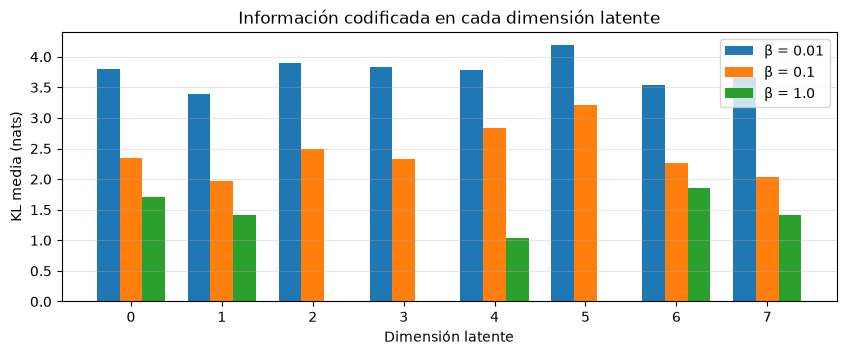

In [9]:
fig, ax = plt.subplots(figsize=(10, 3.5))
width = 0.25
for k, (beta, model) in enumerate(vaes.items()):
    mu, logvar = encode_mu(model, x_test)
    kl_per_dim = (-0.5 * (1 + logvar - mu.pow(2) - logvar.exp())).mean(dim=0).cpu()
    ax.bar(np.arange(8) + (k - 1) * width, kl_per_dim, width, label=f"β = {beta}")
ax.set_xlabel("Dimensión latente")
ax.set_ylabel("KL media (nats)")
ax.set_title("Información codificada en cada dimensión latente")
ax.legend()
ax.grid(True, axis="y", alpha=0.3)
plt.show()

## 5. Generación de imágenes nuevas

Es la capacidad que distingue al VAE del autoencoder del cuaderno 05: se muestrean vectores $z \sim \mathcal{N}(0, I)$ **que no corresponden a ninguna imagen real** y se decodifican. Se usa la misma semilla para los tres modelos, así que cada casilla de la rejilla corresponde al mismo $z$ en los tres casos.

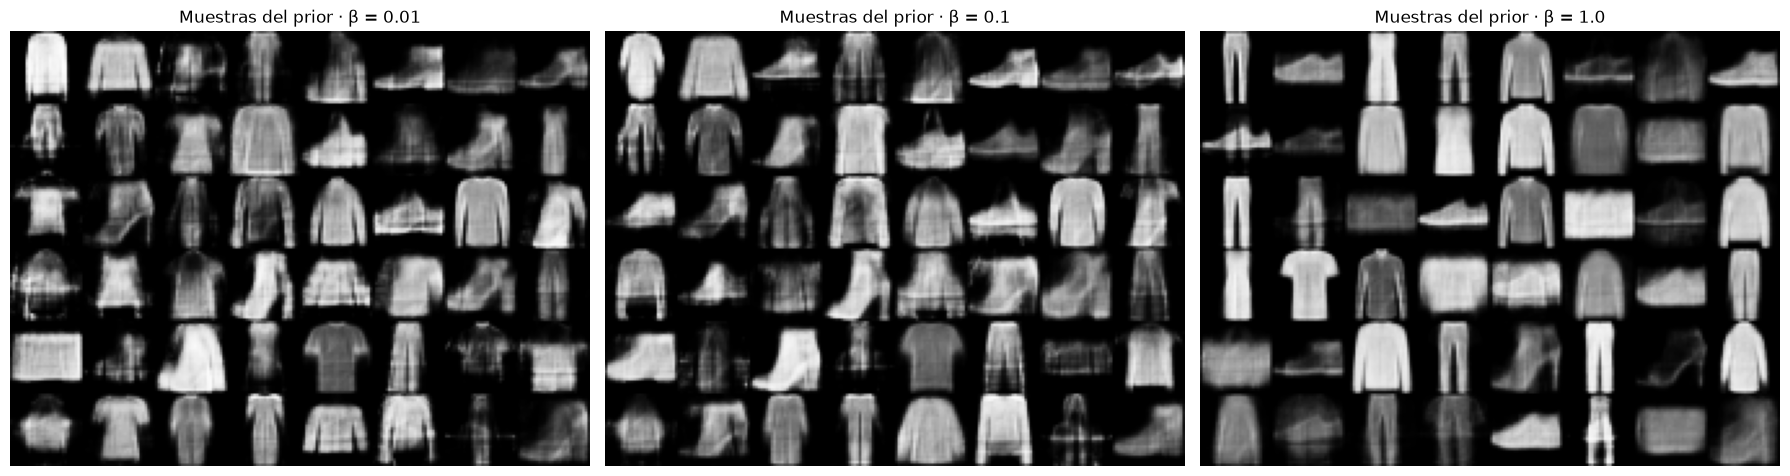

In [10]:
z_prior = torch.randn(48, 8, generator=torch.Generator().manual_seed(SEED)).to(device)

fig, axes = plt.subplots(1, len(BETAS), figsize=(6 * len(BETAS), 5))
for ax, (beta, model) in zip(axes, vaes.items()):
    imgs = decode(model, z_prior).cpu().squeeze(1)
    grid = imgs.reshape(6, 8, 28, 28).permute(0, 2, 1, 3).reshape(6 * 28, 8 * 28)
    ax.imshow(grid, cmap="gray", vmin=0, vmax=1)
    ax.set_title(f"Muestras del prior · β = {beta}")
    ax.axis("off")
plt.tight_layout()
plt.show()

### El compromiso de $\beta$

La tabla, las curvas y las muestras cuentan la misma historia:

- **$\beta = 0.01$ (la configuración original)**: la KL apenas pesa y el modelo se comporta casi como un autoencoder estándar. Usa las 8 dimensiones, reconstruye mejor y su KL es la más alta. Pero las distribuciones de cada imagen no cubren $\mathcal{N}(0, I)$, así que muchas muestras del prior caen en "huecos" que el decodificador no ha aprendido y salen como híbridos deformes.
- **$\beta = 0.1$**: la reconstrucción y la exactitud KNN son prácticamente iguales, pero la KL baja en torno a un tercio. Esa regularidad extra sale casi gratis. Las muestras mejoran algo, aunque sigue habiendo muchos híbridos.
- **$\beta = 1$**: la regularización domina. **Varias dimensiones se desactivan** (su KL es prácticamente cero en la gráfica de barras): el modelo prefiere no usar una dimensión antes que pagar su coste en KL, un *posterior collapse* parcial. La reconstrucción empeora cerca de un 30 % y la exactitud KNN baja unos puntos. A cambio, **casi todas las muestras del prior son prendas reconocibles**: con menos dimensiones, pero bien cubiertas por el prior, el espacio latente no tiene huecos.

No existe un $\beta$ correcto en abstracto: depende de si el objetivo es reconstruir, generar o extraer características. Como el interés de un VAE es generar, el resto del cuaderno usa $\beta = 1$.

In [11]:
MAIN_BETA = 1.0
vae = vaes[MAIN_BETA]
mu_test, logvar_test = encode_mu(vae, x_test)
mu_np, std_np = mu_test.cpu().numpy(), (0.5 * logvar_test).exp().cpu().numpy()

## 6. El espacio latente como distribución

En el DAE cada imagen era un punto. En el VAE cada imagen es una **gaussiana**: el punto representa solo su media, y la varianza indica la incertidumbre del codificador. La primera figura muestra las medias para pares de dimensiones. Las dimensiones desactivadas se reconocen por la escala de sus ejes: todas las imágenes quedan en un rango de centésimas alrededor de 0, frente a varias unidades en las dimensiones activas. El decodificador no puede extraer información útil de variaciones tan pequeñas comparadas con el ruido de muestreo ($\sigma \approx 1$). En la segunda se dibuja, para 40 imágenes al azar, una elipse de $\pm 2\sigma$ alrededor de su media: la "nube" que ocupa cada imagen y que obliga al decodificador a funcionar bien también en su entorno.

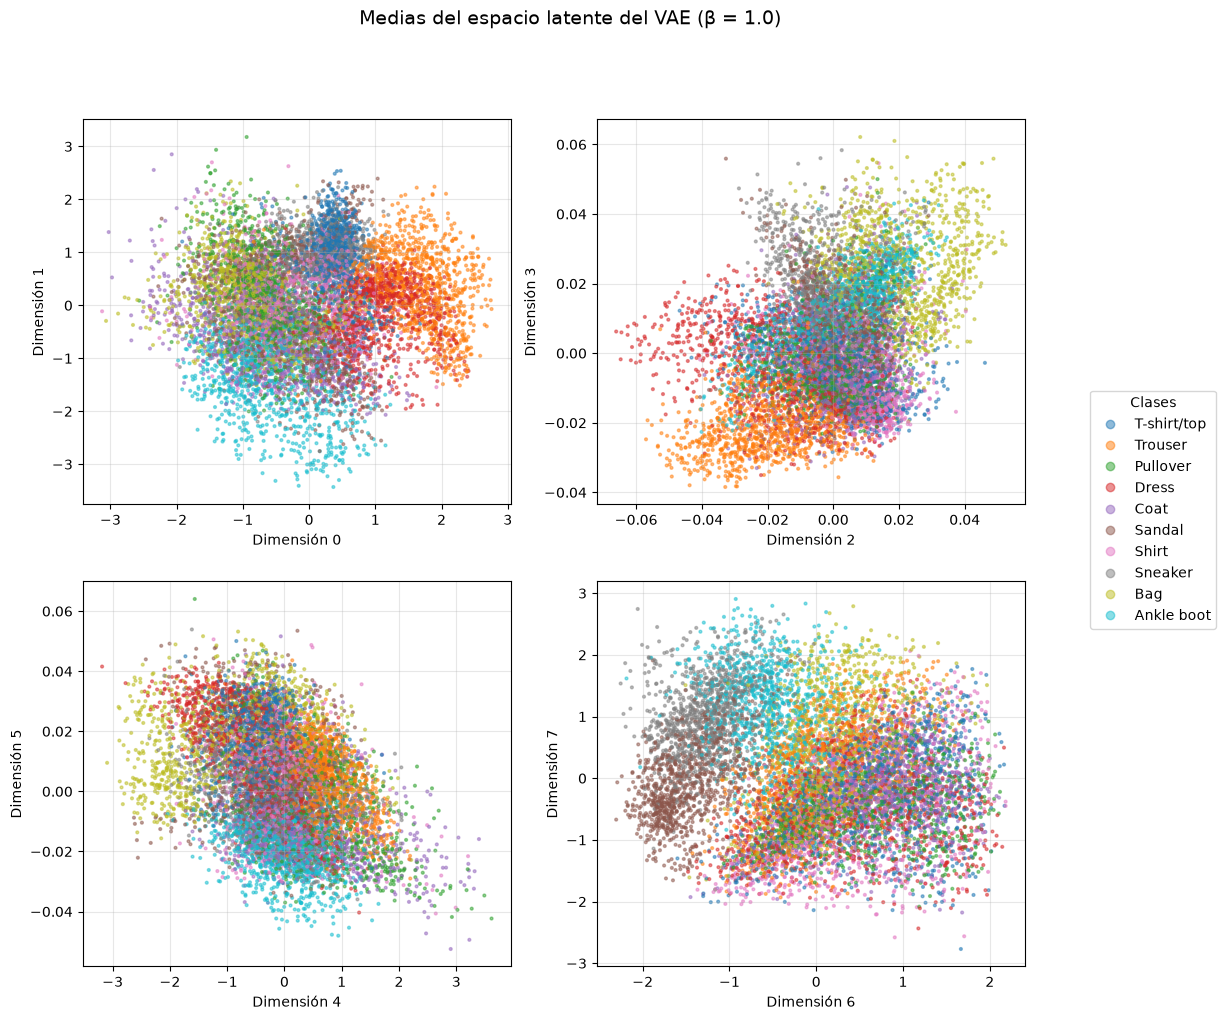

In [12]:
fig, axes = plt.subplots(2, 2, figsize=(13, 11))
for i, ax in enumerate(axes.flat):
    sc = ax.scatter(mu_np[:, 2 * i], mu_np[:, 2 * i + 1], c=y_test, cmap="tab10", s=4, alpha=0.5)
    ax.set_xlabel(f"Dimensión {2 * i}")
    ax.set_ylabel(f"Dimensión {2 * i + 1}")
    ax.grid(True, alpha=0.3)
fig.legend(sc.legend_elements()[0], CLASSES, title="Clases", loc="center right")
fig.suptitle(f"Medias del espacio latente del VAE (β = {MAIN_BETA})", fontsize=14)
plt.subplots_adjust(right=0.85)
plt.show()

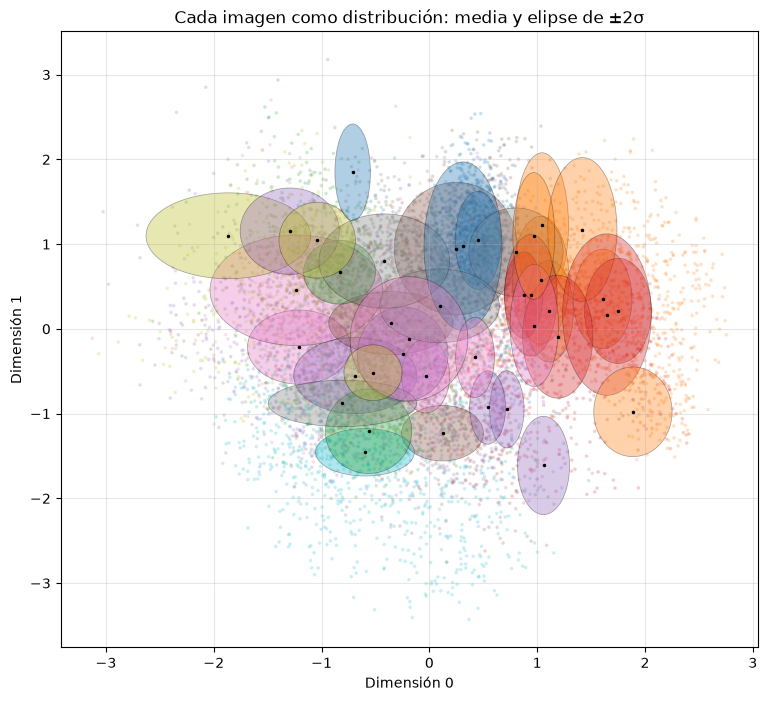

In [13]:
d0, d1 = np.argsort(mu_np.var(axis=0))[::-1][:2]   # las dos dimensiones con más varianza
cmap = plt.get_cmap("tab10")
sample = np.random.default_rng(SEED).choice(len(mu_np), 40, replace=False)

fig, ax = plt.subplots(figsize=(9, 8))
ax.scatter(mu_np[:, d0], mu_np[:, d1], c=y_test, cmap="tab10", s=3, alpha=0.15)
for i in sample:
    ax.add_patch(Ellipse((mu_np[i, d0], mu_np[i, d1]), 4 * std_np[i, d0], 4 * std_np[i, d1],
                         facecolor=cmap(y_test[i]), edgecolor="black", alpha=0.35, lw=0.5))
    ax.plot(mu_np[i, d0], mu_np[i, d1], "k.", ms=3)
ax.set_xlabel(f"Dimensión {d0}")
ax.set_ylabel(f"Dimensión {d1}")
ax.set_title("Cada imagen como distribución: media y elipse de ±2σ")
ax.grid(True, alpha=0.3)
plt.show()

### Reducción de dimensiones

Mismo análisis que en el cuaderno 05, aplicado a las medias $\mu$: PCA como proyección lineal global y t-SNE como proyección que conserva vecindades.

Varianza explicada por PC1 y PC2: [24.73 22.37] %


t-SNE: 30.8 s


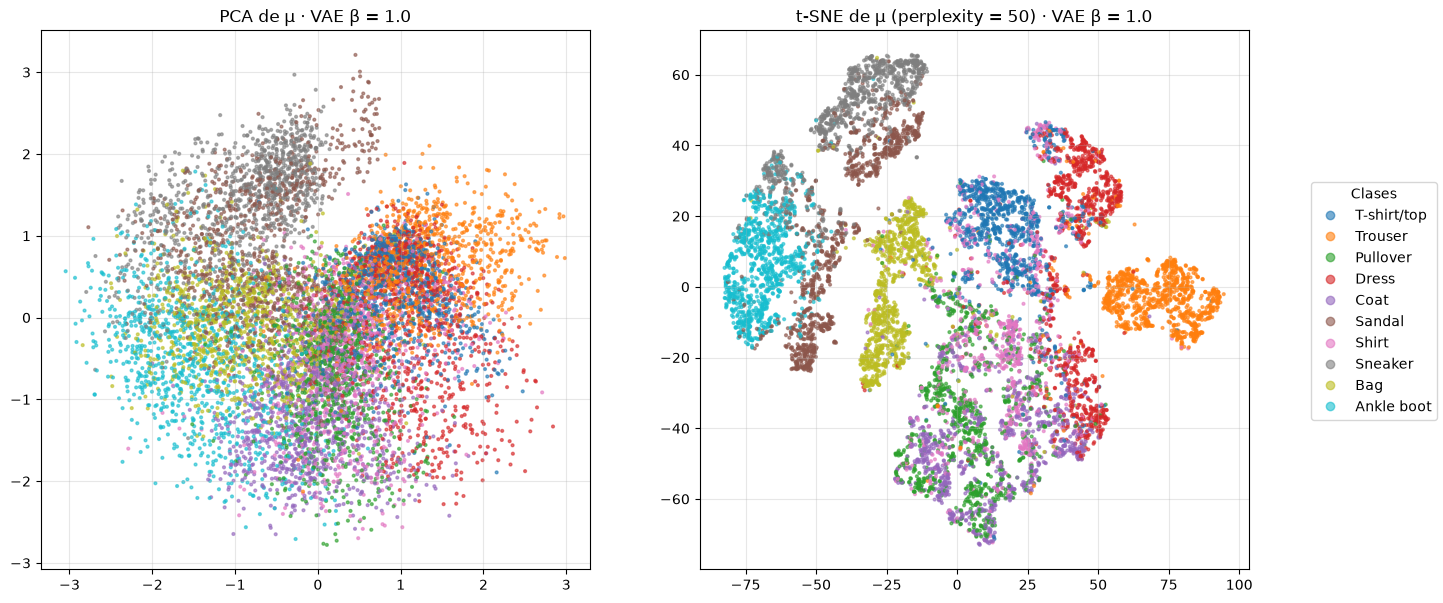

In [14]:
pca = PCA(n_components=2).fit(mu_np)
print("Varianza explicada por PC1 y PC2:", (pca.explained_variance_ratio_ * 100).round(2), "%")
start = time.time()
z_tsne = TSNE(n_components=2, perplexity=50, init="pca", learning_rate="auto", random_state=SEED).fit_transform(mu_np)
print(f"t-SNE: {time.time() - start:.1f} s")

fig, axes = plt.subplots(1, 2, figsize=(16, 7))
for ax, emb, title in [(axes[0], pca.transform(mu_np), "PCA de μ"), (axes[1], z_tsne, "t-SNE de μ (perplexity = 50)")]:
    sc = ax.scatter(emb[:, 0], emb[:, 1], c=y_test, cmap="tab10", s=4, alpha=0.6)
    ax.set_title(f"{title} · VAE β = {MAIN_BETA}")
    ax.grid(True, alpha=0.3)
fig.legend(sc.legend_elements()[0], CLASSES, title="Clases", loc="center right")
plt.subplots_adjust(right=0.88)
plt.show()

## 7. Interpolación entre clases

La misma prueba que en el cuaderno 05: recorrer la línea recta entre los prototipos de *Pullover* y *Sneaker*. En un espacio latente continuo, los puntos intermedios deberían decodificarse como transiciones graduales y plausibles.

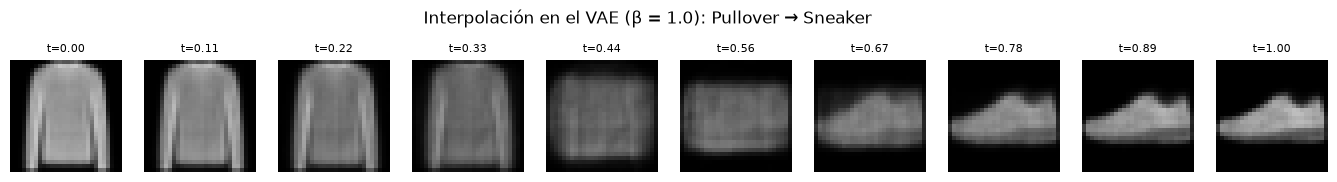

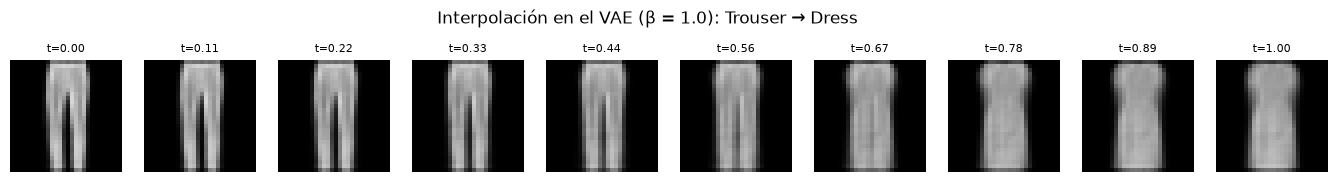

In [15]:
def interpolate(model, class_a, class_b, steps=10):
    z_a = mu_test[torch.from_numpy(y_test == class_a).to(device)].mean(dim=0)
    z_b = mu_test[torch.from_numpy(y_test == class_b).to(device)].mean(dim=0)
    ts = torch.linspace(0, 1, steps, device=device).unsqueeze(1)   # nombre propio: no sobrescribe el peso de la KL
    imgs = decode(model, (1 - ts) * z_a + ts * z_b).cpu()
    fig, axes = plt.subplots(1, steps, figsize=(1.7 * steps, 2.2))
    for ax, img, t in zip(axes, imgs, ts):
        ax.imshow(img.squeeze(), cmap="gray", vmin=0, vmax=1)
        ax.set_title(f"t={t.item():.2f}", fontsize=8)
        ax.axis("off")
    fig.suptitle(f"Interpolación en el VAE (β = {MAIN_BETA}): {CLASSES[class_a]} → {CLASSES[class_b]}")
    plt.show()


interpolate(vae, 2, 7)   # Pullover -> Sneaker
interpolate(vae, 1, 3)   # Trouser -> Dress

## 8. Del cuaderno al despliegue: generar desde un *checkpoint*

Para usar el VAE como generador en otra aplicación basta con el **decodificador** y la dimensión latente. Se guardan, se recargan en un modelo nuevo y se generan imágenes sin volver a tocar los datos de entrenamiento.

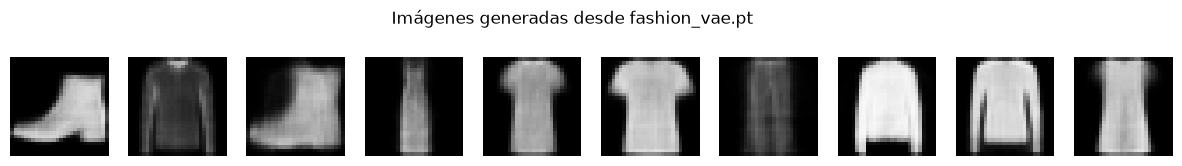

In [16]:
ckpt_path = CKPT_DIR / "fashion_vae.pt"
torch.save({"model_state": vae.state_dict(), "latent_dim": vae.latent_dim, "beta": MAIN_BETA}, ckpt_path)

checkpoint = torch.load(ckpt_path, map_location=device, weights_only=True)
generator = VAE(checkpoint["latent_dim"]).to(device)
generator.load_state_dict(checkpoint["model_state"])

new_images = decode(generator, torch.randn(10, checkpoint["latent_dim"], device=device)).cpu()
fig, axes = plt.subplots(1, 10, figsize=(15, 2))
for ax, img in zip(axes, new_images):
    ax.imshow(img.squeeze(), cmap="gray", vmin=0, vmax=1)
    ax.axis("off")
fig.suptitle(f"Imágenes generadas desde {ckpt_path.name}")
plt.show()

## 9. Conclusiones

- **Del punto a la distribución.** El VAE codifica cada imagen como una gaussiana y regulariza esas gaussianas hacia $\mathcal{N}(0, I)$. El resultado es un espacio latente compacto y continuo del que se puede **muestrear**, que es lo que le faltaba al DAE.
- **La reparametrización hace entrenable el modelo.** Mover la aleatoriedad a una entrada externa convierte el muestreo en una operación diferenciable.
- **$\beta$ es el compromiso central.** Controla el equilibrio entre reconstrucciones fieles (β bajo) y un espacio latente regular y apto para generar (β alto). Si la regularización es fuerte, el modelo desactiva dimensiones. La configuración original ($\beta = 0.01$) reconstruía bien pero generaba mal. Monitorizar por separado reconstrucción, KL, unidades activas y calidad de las muestras es imprescindible para elegirlo, porque ninguna métrica aislada lo refleja todo.
- **Continuidad, con límites.** Entre clases de forma parecida (pantalón → vestido), la interpolación es gradual y cada paso es una prenda plausible. Entre clases muy distintas (jersey → zapatilla) sigue habiendo pasos intermedios que no son ninguna prenda: la línea recta entre dos prototipos tan alejados atraviesa una región de baja densidad incluso en un espacio regularizado. Recorrer el espacio latente de forma "natural" exigiría seguir caminos por zonas de alta densidad, no solo líneas rectas.
- **Nitidez.** Las imágenes generadas son reconocibles pero borrosas. Es una limitación conocida de los VAE con verosimilitud gaussiana: el término MSE promedia los detalles inciertos. Los modelos de difusión, que se apoyan en la misma idea de *score* vista en el cuaderno 05, y las GAN producen imágenes mucho más nítidas.
- **Representación reutilizable.** Las medias $\mu$ funcionan como características para el mismo pipeline KNN del cuaderno 05. Con β bajo, la exactitud es prácticamente la del DAE. Con β = 1 baja unos puntos, porque el prior acerca entre sí los grupos de clases y hay menos dimensiones útiles. La representación óptima para clasificar no es la óptima para generar.

### Recorrido del curso

| Cuaderno | Problema | Idea clave | Etapa de pipeline añadida |
|---|---|---|---|
| 01 | Regresión 1D multisalida | Leer el error en su contexto | Particiones, estandarización, *checkpointing* |
| 02 | Imagen como función | La codificación de la entrada decide qué se aprende | `Dataset` propio, barrido de hiperparámetros, reentrenamiento |
| 03 | Clasificación CIFAR-10 | El pipeline de datos limita al hardware | `Compose`, *early stopping*, métricas por clase, persistencia |
| 04 | Jerarquía CIFAR-100 | Combinar modelos exige errores no correlacionados | Partición compartida, composición de modelos, métricas jerárquicas |
| 05 | DAE Fashion-MNIST | Eliminar ruido es estimar la media a posteriori | Corrupción dinámica, líneas base, `sklearn.Pipeline` |
| 06 | VAE Fashion-MNIST | Regularizar el espacio latente permite generar | Pérdidas compuestas, diagnóstico, generación desde *checkpoint* |